### IPD441 - Visión por Computador
# Clase 4: Open-World Vision
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# ¿Qué es Open-World Vision?

Open-World Vision se refiere a la capacidad de un sistema de visión por computadora para reconocer, clasificar y analizar objetos, escenas o conceptos más allá de un conjunto fijo de categorías vistas en el entrenamiento; similar a cómo nuestro cerebro rellena los vacíos cuando ve algo desconocido.

<div align="center">
    <img src="img/Pareidolia-Duck.jpg" alt="" width="50%" align="center" />
</div>

# Aplicaciones de Open-World Vision

- Open-World Image Classification (Clasificación de imágenes con clases desconocidas).
- Open-World Semantic Segmentation (Segmentación flexible de objetos no vistos).
- Open-Vocabulary Object Detection (OVOD) (Detección sin etiquetas fijas).



# ¿Qué son los Embeddings?

Los embeddings son representaciones numéricas de datos en un espacio continuo. Transforman imágenes y textos en vectores en un espacio de alta dimensión, donde elementos similares están más cerca entre sí.

<div align="center">
    <img src="img/embedding_signs.avif" alt="" width="60%" align="center" />
</div>

# CLIP: Connecting text and images

CLIP (Contrastive Language-Image Pre-Training) es una red neuronal que aprende conceptos visuales de manera eficiente a partir de la supervisión del lenguaje natural. Utiliza una técnica llamada aprendizaje contrastivo para unir imágenes con descripciones de texto.

<div align="center">
    <img src="img/text-images-space.png" alt="" width="30%" align="center" />
</div>

## Contrastive Learning

El aprendizaje contrastivo busca aprender representaciones útiles de datos, maximizando la similitud entre muestras similares y minimizando la similitud entre muestras diferentes.

<div align="center">
    <img src="img/representation.png" alt="" width="50%" align="center" />
</div>

<div align="center">
    <img src="img/contrastive.png" alt="" width="100%" align="center" />
</div>

### Representation space
Se contrastan muestras similares y diferentes. Específicamente, se intenta acercar muestras similares entre sí en el espacio de representación y alejar las diferentes.

<div align="center">
    <img src="img/representation-space.png" alt="" width="50%" align="center" />
</div>


# CLIP

**Dos encoders separados:**

- **Image Encoder (Visión):** Extrae representaciones de la imagen usando una red neuronal profunda (ej. ViT o ResNet).
- **Text Encoder (Lenguaje):** Convierte el texto en embeddings semánticos usando un modelo de Transformer.

**Espacio Latente Compartido:**

- CLIP aprende a mapear imágenes y textos a un espacio vectorial común.
- Se entrena con un objetivo contrastivo: imágenes y textos relacionados se acercan, mientras que los no relacionados se alejan.


# Ejemplo de uso de CLIP

In [1]:
#!pip install ftfy regex tqdm matplotlib selectivesearch
# pip install git+https://github.com/openai/CLIP.git

In [2]:
import clip
import torch
from PIL import Image
import matplotlib.pyplot as plt

In [3]:
def plot_clip_infer(img_path, classes = ["animales", "vehiculos", "frutas", "personas"]):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, preprocess = clip.load("ViT-B/32", device=device)
    
    imagen = Image.open(img_path)

    # Mostrar la imagen con matplotlib
    plt.imshow(imagen)
    plt.axis('off')  # Ocultar los ejes
    plt.show()
    
    # Cargar imagen de prueba
    image = preprocess(Image.open(img_path)).unsqueeze(0).to(device)
    # Definir etiquetas en lenguaje natural
    textos = classes
    text_tokens = clip.tokenize(textos).to(device)
    # Pasar imagen y texto por el modelo
    with torch.no_grad():
        image_features = model.encode_image(image)
        text_features = model.encode_text(text_tokens)

    # Calcular similitud de coseno entre imagen y textos
    similaridades = (image_features @ text_features.T).softmax(dim=-1)
    mejor_coincidencia = textos[similaridades.argmax()]

    print(f"La imagen parece ser: {mejor_coincidencia}")
    Image.open(img_path)

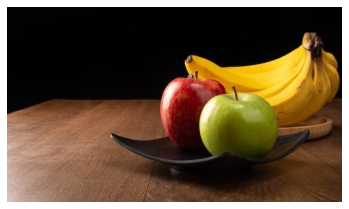

La imagen parece ser: frutas


In [4]:
plot_clip_infer("img/apples-banana.jpg", classes=["animales", "vehiculos", "frutas", "personas"])

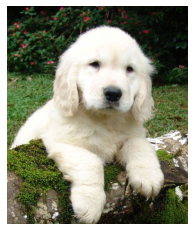

La imagen parece ser: animales


In [5]:
plot_clip_infer("img/golden.jpg", classes=["animales", "vehiculos", "frutas", "personas"])

# Open-Vocabulary Object Detection (OVOD)

**¿Qué es Open-Vocabulary Object Detection?**
Es la capacidad de un modelo de detección de objetos para identificar categorías que no ha visto durante el entrenamiento, usando descripciones en lenguaje natural en lugar de etiquetas fijas.

# ¿Por qué necesitamos Open-Vocabulary Object Detection?

- Los modelos tradicionales solo detectan clases predefinidas.
- Queremos reconocer nuevos objetos sin reentrenamiento.
- Aplicaciones en robótica, medicina, y más.

# Diferencias entre Closed-Vocabulary y Open-Vocabulary

**Closed-Vocabulary (Convencional)**

- Solo detecta clases entrenadas.
- Depende de etiquetas fijas.
- Ejemplo: "laptop", "celular", "teclado".

**Open-Vocabulary (OVOD)**

- Detecta nuevas clases sin reentrenar.
- Usa lenguaje natural para describir objetos.
- Ejemplo: "Objetos relacionados con tecnología".

# Zero-shot

"Zero-shot" se refiere a la capacidad de un modelo para realizar tareas sin haber sido específicamente entrenado para esas tareas en particular. En otras palabras, el modelo es capaz de generalizar su conocimiento y aplicarlo a tareas nuevas sin haber recibido ejemplos específicos durante el entrenamiento.

En el caso de CLIP, el modelo ha sido entrenado para entender la relación entre imágenes y texto. Por lo tanto, puede realizar tareas como resolver un CAPTCHA.

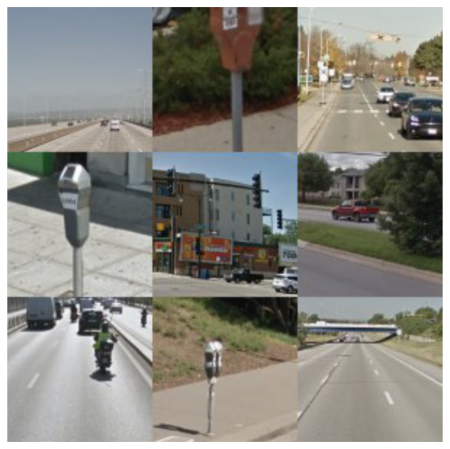

In [6]:
parking = Image.open("img/parking_meters.png").convert("RGB")
plt.figure(figsize=(8,8))
plt.axis('off')
plt.imshow(parking)
plt.show()

In [7]:
from reCAPTCHA import *
device = "cuda" if torch.cuda.is_available() else "cpu"

In [8]:
ViT_B, ViT_B_preprocess = clip.load("ViT-B/32", device=device, jit=False)

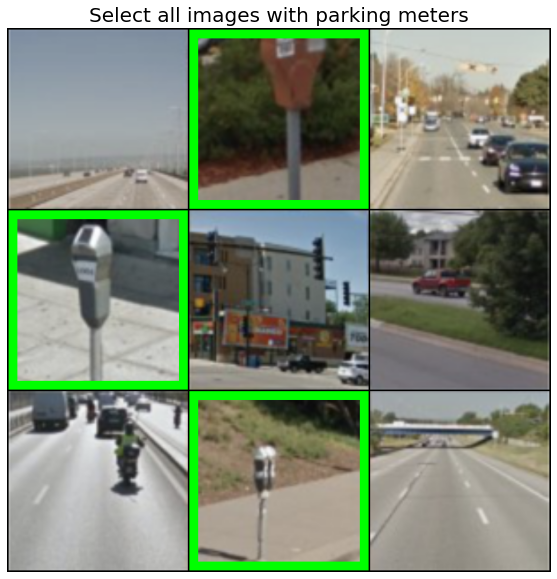

In [9]:
solve_reCAPTCHA(parking, "Select all images with parking meters", ViT_B, device, topk =  3)

In [10]:
from Detector import *

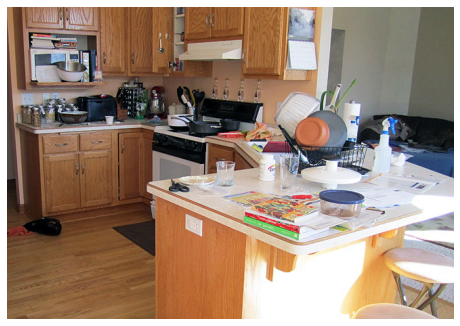

In [11]:
kitchen = load_image("img/kitchen.jpeg")
plt.figure(figsize=(8,8))
plt.axis('off')
plt.imshow(kitchen)
plt.show()

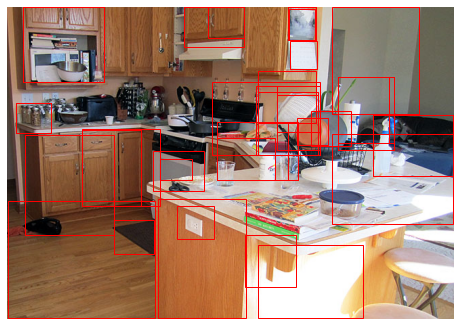

In [12]:
candidates = plot_selective_search(kitchen)

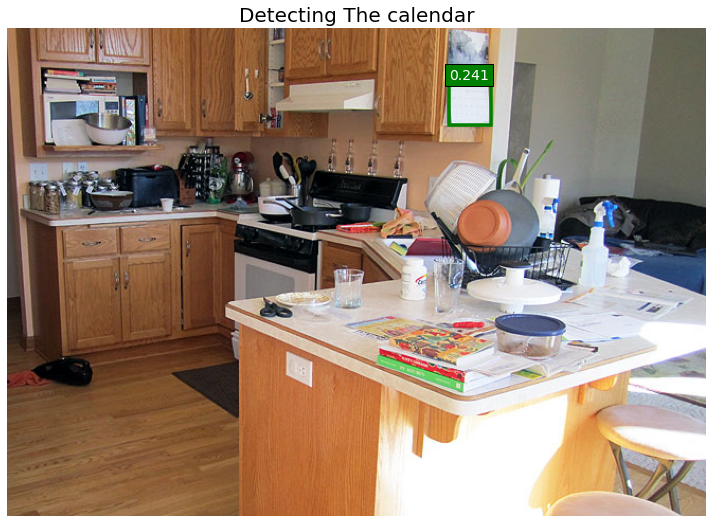

In [13]:
detect(kitchen, candidates, "The calendar", ViT_B, ViT_B_preprocess, device)

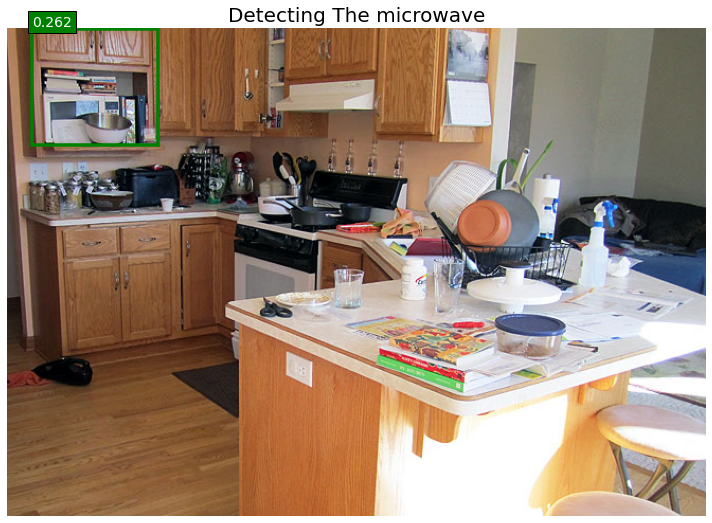

In [14]:
detect(kitchen, candidates, "The microwave", ViT_B, ViT_B_preprocess, device)

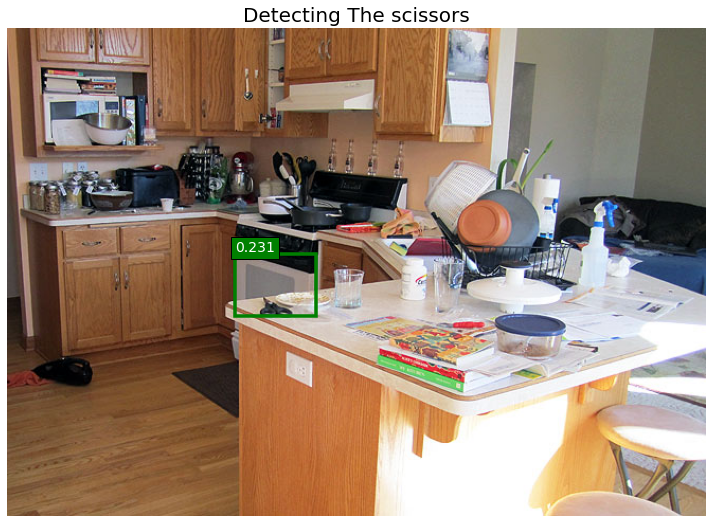

In [15]:
detect(kitchen, candidates, "The scissors", ViT_B, ViT_B_preprocess, device)

# YOLO-World

El YOLO-Modelo Mundial permite detección de vocabulario abierto.

<div align="center">
    <img src="img/YOLO-World.jpg" alt="" width="70%" align="center" />
</div>

# Arquitectura de YOLO-World: Open-Vocabulary Object Detection
🖼 **Entrada:** Imagen de prueba con objetos desconocidos.

🟢 **Extracción de características (YOLO Backbone):**

- Se procesan características en múltiples escalas.
- Se extraen representaciones profundas de la imagen.

🔠 **Incorporación de conocimiento textual (Text Encoder):**

- Se extraen sustantivos de descripciones de texto.
- Se generan embeddings del vocabulario en un espacio semántico.

🔄 **Fusión de visión y lenguaje (Vision-Language PAN):**

- Se integran los embeddings de imagen y texto.
- Se produce una representación conjunta que asocia conceptos visuales con palabras.

📌 **Detección y asociación (Region-Text Matching):**

- Se comparan embeddings de regiones de la imagen con embeddings de vocabulario.
- Se asignan etiquetas semánticas a regiones detectadas, incluso si no estaban en el entrenamiento.

📦 **Predicción de cajas y texto (Box Head & Text Contrastive Head):**

- Se generan las coordenadas de las cajas delimitadoras.
- Se optimiza la asociación imagen-texto mediante aprendizaje contrastivo.

🔍 **Resultado:** Detección de objetos con vocabulario abierto, permitiendo reconocer nuevas clases sin necesidad de reentrenamiento.

In [16]:
from yoloworld import *

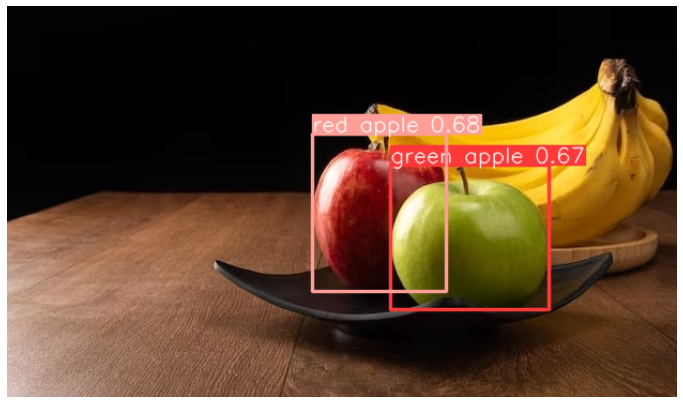

In [17]:
plot_yolo_world(path="img/apples-banana.jpg", classes=["green apple", "red apple"])